# 06 - Deliveries vs Consumption & Stockpile Dynamics

Are deliveries keeping pace with consumption, and what do stockpiles signal? Uses U.S. Total rows (state-level electric-power stocks are largely missing).

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data, CLEAN_SECTOR_BREAKDOWN
from src.taxonomy import add_location_level, filter_location
from src.clean import clean
df = add_location_level(clean(load_coal_data(DATA)))
us = filter_location(df, 'national')
# Electric power (98) is the volume driver and has stocks at US level
ep = us[us['sector'] == 98].set_index('period').sort_index()
ep[['consumption', 'receipts', 'stocks']].astype(float)

,consumption,receipts,stocks
period,,,
2020,4.358268e+08,433114928.0,131430673.0
2021,5.014345e+08,454684316.0,91884252.0
2022,4.728337e+08,462984791.0,88860583.0
2023,3.872053e+08,425198173.0,133028387.0
2024,3.732582e+08,363248003.0,127825935.0
2025,4.153955e+08,389930320.0,109733181.0


In [4]:
# Implied net stock build/draw = receipts - consumption
ep['net_build'] = ep['receipts'] - ep['consumption']
# Days-of-burn = stocks / (consumption / 365)
ep['days_of_burn'] = ep['stocks'] * 365 / ep['consumption']
ep[['consumption', 'receipts', 'stocks', 'net_build', 'days_of_burn']].round(0)

,consumption,receipts,stocks,net_build,days_of_burn
period,,,,,
2020,435826849.0,433114928.0,131430673.0,-2711921.0,110.0
2021,501434545.0,454684316.0,91884252.0,-46750229.0,67.0
2022,472833705.0,462984791.0,88860583.0,-9848914.0,69.0
2023,387205305.0,425198173.0,133028387.0,37992868.0,125.0
2024,373258211.0,363248003.0,127825935.0,-10010208.0,125.0
2025,415395510.0,389930320.0,109733181.0,-25465190.0,96.0


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\06_stocks_trend.png


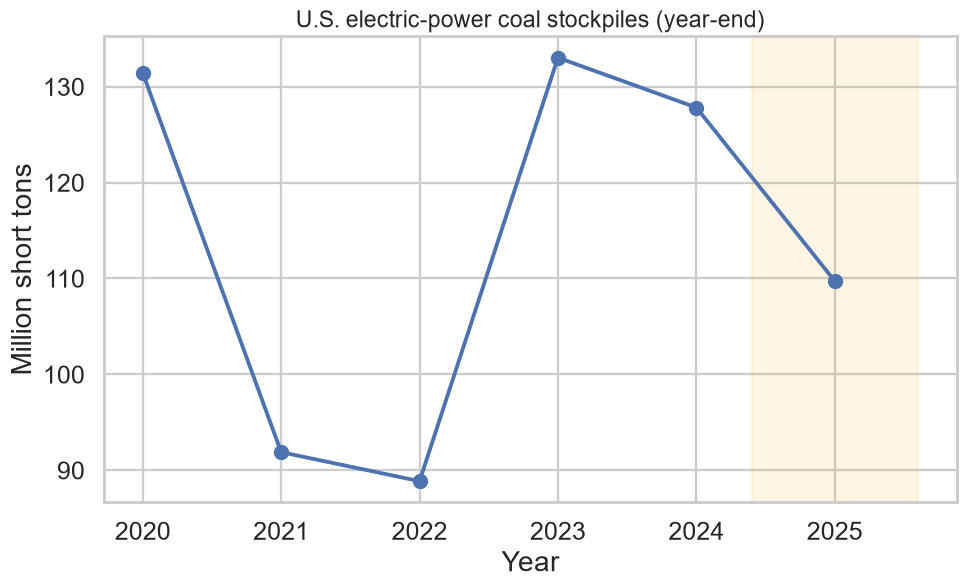

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(ep.index, ep['stocks'] / 1e6, marker='o', lw=2.5, color='#4c72b0', label='Year-end stocks')
ax.set_title('U.S. electric-power coal stockpiles (year-end)', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('Million short tons')
ax.axvspan(2024.4, 2025.6, color='orange', alpha=0.10)
savefig('06_stocks_trend.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\06_days_of_burn.png


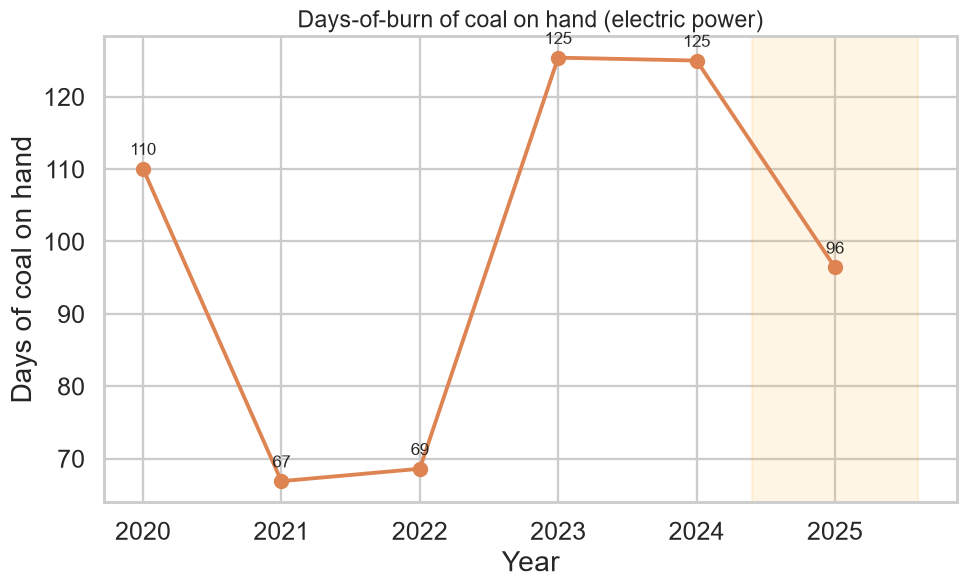

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(ep.index, ep['days_of_burn'], marker='o', lw=2.5, color='#dd8452')
for x, y in zip(ep.index, ep['days_of_burn']):
    ax.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=11)
ax.set_title('Days-of-burn of coal on hand (electric power)', fontsize=15)
ax.set_xlabel('Year'); ax.set_ylabel('Days of coal on hand')
ax.axvspan(2024.4, 2025.6, color='orange', alpha=0.10)
savefig('06_days_of_burn.png')

saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\06_receipts_vs_consumption.png


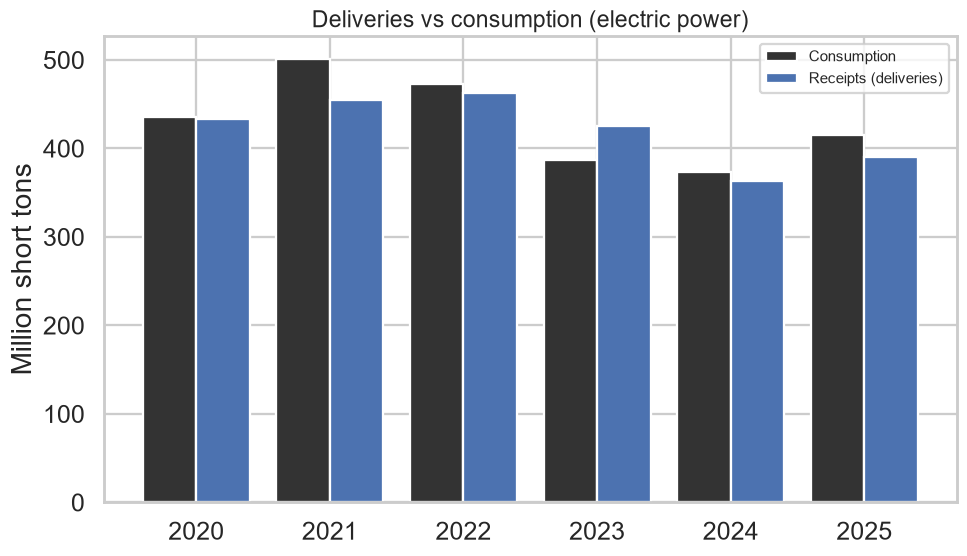

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(ep.index))
w = 0.4
ax.bar(x - w/2, ep['consumption'] / 1e6, w, label='Consumption', color='#333333')
ax.bar(x + w/2, ep['receipts'] / 1e6, w, label='Receipts (deliveries)', color='#4c72b0')
ax.set_xticks(x); ax.set_xticklabels(ep.index)
ax.set_title('Deliveries vs consumption (electric power)', fontsize=15)
ax.set_ylabel('Million short tons'); ax.legend(fontsize=10)
savefig('06_receipts_vs_consumption.png')

In [8]:
# Validation: days-of-burn in a plausible range; NaN stocks excluded
dob = ep['days_of_burn'].dropna()
print('days-of-burn range:', round(dob.min(), 1), '-', round(dob.max(), 1))
assert (dob > 0).all() and (dob < 400).all(), 'implausible days-of-burn'
print('OK - days-of-burn plausible; NaN stocks excluded from averages.')

days-of-burn range: 66.9 - 125.4
OK - days-of-burn plausible; NaN stocks excluded from averages.


**Takeaways**
- When receipts run below consumption, stockpiles are drawn down; when receipts exceed consumption, stocks build. Days-of-burn shows how many days of coal the system holds - a rising figure can mean demand is falling faster than purchases are being cut.
- State-level electric-power stocks are largely missing, so the national stockpile story relies on U.S. Total rows (a documented limitation).